In [1]:
!pip install -q pandas numpy scikit-learn xgboost lightgbm \ matplotlib seaborn tsfresh adversarial-robustness-toolbox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.6 MB/s eta 0:00:00


In [2]:
from google.colab import drive
import os
import shutil

mountpoint = '/content/drive'

                                                                        
if os.path.exists(mountpoint):
    try:
                                                                    
        if os.path.ismount(mountpoint):
            drive.flush_and_unmount()
            print(f"Drive unmounted successfully from {mountpoint}.")
                                                               
        elif os.path.isdir(mountpoint) and os.listdir(mountpoint):
            print(f"Mountpoint {mountpoint} contains files, attempting to clear.")
                                                                       
            for item in os.listdir(mountpoint):
                item_path = os.path.join(mountpoint, item)
                if os.path.isfile(item_path) or os.path.islink(item_path):
                    os.remove(item_path)
                elif os.path.isdir(item_path):
                    shutil.rmtree(item_path)
            print(f"Contents of {mountpoint} cleared.")
    except Exception as e:
        print(f"Error during unmount/clear process: {e}. Proceeding with mount.")

                                                        
os.makedirs(mountpoint, exist_ok=True)

                       
drive.mount(mountpoint, force_remount=True)
PROJECT_DIR = os.path.join(mountpoint, 'MyDrive/man-bot-detection')

Mounted at /content/drive


In [3]:
                                           
!pip install -q datasets huggingface_hub

                                                                
                                                                           
                                                                               
                                                                        
                                                                         
                                                                             
                                                                  
import os
from datasets import load_dataset, load_from_disk

CAPTCHA_CACHE_DIR = '/content/drive/MyDrive/man-bot-detection/data/raw/captchasolve30k_hf_cache'

if os.path.isdir(CAPTCHA_CACHE_DIR) and os.listdir(CAPTCHA_CACHE_DIR):
    print(f"✅ Знайдено кеш CaptchaSolve30k на Drive: {CAPTCHA_CACHE_DIR}")
    print("   Завантажуємо з Drive (без звернення до HuggingFace)...")
    dataset = load_from_disk(CAPTCHA_CACHE_DIR)
else:
    print("ℹ️ Кешу на Drive ще немає — завантажуємо з HuggingFace один раз "
          "(це займе певний час, ~4.8 ГБ) і зберігаємо на Drive для наступних запусків.")
    dataset = load_dataset("Capycap-AI/CaptchaSolve30k")
    os.makedirs(CAPTCHA_CACHE_DIR, exist_ok=True)
    dataset.save_to_disk(CAPTCHA_CACHE_DIR)
    print(f"✅ Збережено на Drive: {CAPTCHA_CACHE_DIR}")
    print("   Наступні запуски цієї комірки будуть читати звідси, а не з HuggingFace.")

                                     
print(dataset)
print(f"Кількість зразків у тренувальному наборі: {len(dataset['train'])}")
                                 
print(dataset['train'][0])

ℹ️ Кешу на Drive ще немає — завантажуємо з HuggingFace один раз (це займе певний час, ~4.8 ГБ) і зберігаємо на Drive для наступних запусків.


README.md:   0%|          | 0.00/6.33k [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 3.21GB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl: reconstructing file:   0%|          |  0.00B /  802MB            

validation.jsonl: downloading bytes:           |  0.00B            

... (5 outputs left out)

Saving the dataset (0/3 shards):   0%|          | 0/20000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5000 [00:00<?, ? examples/s]

✅ Збережено на Drive: /content/drive/MyDrive/man-bot-detection/data/raw/captchasolve30k_hf_cache
   Наступні запуски цієї комірки будуть читати звідси, а не з HuggingFace.
DatasetDict({
    train: Dataset({
        features: ['index', 'tickInputs', 'inputStream', 'inputSampleCount', 'duration', 'touchscreen', 'gameType', 'physicsTickCount', 'puzzleSeed'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['index', 'tickInputs', 'inputStream', 'inputSampleCount', 'duration', 'touchscreen', 'gameType', 'physicsTickCount', 'puzzleSeed'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['index', 'tickInputs', 'inputStream', 'inputSampleCount', 'duration', 'touchscreen', 'gameType', 'physicsTickCount', 'puzzleSeed'],
        num_rows: 5000
    })
})
Кількість зразків у тренувальному наборі: 20000
{'index': 2169, 'tickInputs': [{'isDown': False, 'sampleIndex': 1, 'x': 0.0, 'y': 0.0}, {'isDown': False, 'sampleIndex': 1, 'x': 0.0, 'y': 0.0}, {'isDow

In [4]:
                                             
!wget https://raw.githubusercontent.com/chrisgdt/DELBOT-Mouse/master/python/parseSamples.py
!wget https://raw.githubusercontent.com/chrisgdt/DELBOT-Mouse/master/python/ganParser.py
!wget https://raw.githubusercontent.com/chrisgdt/DELBOT-Mouse/master/python/botDrawing.py

--2026-08-19 17:11:43--  https://raw.githubusercontent.com/chrisgdt/DELBOT-Mouse/master/python/parseSamples.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1665 (1.6K) [text/plain]
Saving to: ‘parseSamples.py’

parseSamples.py     100%[===================>]   1.63K  --.-KB/s    in 0s      

2026-08-19 17:11:43 (9.69 MB/s) - ‘parseSamples.py’ saved [1665/1665]

--2026-08-19 17:11:43--  https://raw.githubusercontent.com/chrisgdt/DELBOT-Mouse/master/python/ganParser.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5352 (5.2K) [t

In [5]:
                            
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

                                         
                                                                             
                                                                                            
                                                                               
                                                                          
                                                                              
target_folder = '/content/drive/MyDrive/man-bot-detection/data/raw/delbot_mouse'

                                      
import os
os.makedirs(target_folder, exist_ok=True)

                                      
                                                                            
                           
already_present = any(
    os.path.isdir(os.path.join(target_folder, d)) and d.startswith('circles_')
    for d in os.listdir(target_folder)
) if os.path.isdir(target_folder) else False

if already_present:
    print(f"✅ DELBOT-Mouse вже розпакований у {target_folder}, пропускаємо завантаження.")
else:
    archive_path = os.path.join(target_folder, 'dataset.tar.gz')
                                                     
    !wget -O "$archive_path" https://github.com/chrisgdt/DELBOT-Mouse/raw/master/python/dataset.tar.gz

                                                                                      
    archive_size = os.path.getsize(archive_path) if os.path.exists(archive_path) else 0
    if archive_size < 100_000:                                             
        raise RuntimeError(
            f"Завантажений файл підозріло малий ({archive_size} байт) — це, ймовірно, "
            f"HTML-сторінка помилки, а не dataset.tar.gz. Перевір посилання вручну: "
            f"https://github.com/chrisgdt/DELBOT-Mouse/tree/master/python"
        )

                                         
    !tar -xzvf "$archive_path" -C "$target_folder"

                                                                 
    os.remove(archive_path)

                                
!ls -la "$target_folder"

Mounted at /content/drive
✅ DELBOT-Mouse вже розпакований у /content/drive/MyDrive/man-bot-detection/data/raw/delbot_mouse, пропускаємо завантаження.
total 40
drwx------ 2 root root 4096 Jul 29 11:29 circles_bot_gan
drwx------ 2 root root 4096 Nov 30  2022 circles_bot_naturalmousemotion
drwx------ 2 root root 4096 Nov 30  2022 circles_bot_pyhm
drwx------ 2 root root 4096 Nov 22  2022 circles_bot_pynput
drwx------ 2 root root 4096 Nov  2  2022 circles_human_fast
drwx------ 2 root root 4096 Oct 25  2022 circles_human_pc1
drwx------ 2 root root 4096 Jun 15  2023 circles_human_pc2
drwx------ 2 root root 4096 Oct 25  2022 circles_human_pc2_pad
drwx------ 2 root root 4096 Oct 25  2022 circles_human_tel
drwx------ 2 root root 4096 Oct 25  2022 circles_human_vm


In [8]:
!ls -la "$target_folder"

total 352477
-rw------- 1 root root       191 Jul 29 12:13  CACHEDIR.TAG
-rw------- 1 root root  77123859 Aug 28  2023  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
-rw------- 1 root root  58316725 Aug 28  2023  Friday-WorkingHours-Morning.pcap_ISCX.csv
-rw------- 1 root root         1 Jul 29 12:13  .gitignore
-rw------- 1 root root    108784 May 11 12:09 'MachineLearningCSV (1).md5'
-rw------- 1 root root    108784 May 11 12:09 'MachineLearningCSV (1).zip'
-rw------- 1 root root    108784 May 11 12:09  MachineLearningCSV.md5
-rw------- 1 root root         0 Jul 29 12:10  MachineLearningCSV.zip
-rw------- 1 root root         0 Jul 29 12:13  MachineLearningCSV.zip.lock
-rw------- 1 root root 225166395 Aug 28  2023  Wednesday-workingHours.pcap_ISCX.csv


In [6]:
                            
                                                                     
                                                                          
                                                                        
                                                                          
                                                                       
                                                                              
                                                                            
                                              
 
                                                                         
                                                 
                                               
                              
 
                                                                      
                                                                      
                                                                       
                                                                         

                                   
                                                         

print("ℹ️ Переміщення у підпапку 'python/' вимкнено (див. коментар вище). "
      "circles_* залишаються напряму в data/raw/delbot_mouse/, як і очікують "
      "наступні комірки.")
!ls -la "$target_folder"

ℹ️ Переміщення у підпапку 'python/' вимкнено (див. коментар вище). circles_* залишаються напряму в data/raw/delbot_mouse/, як і очікують наступні комірки.
total 40
drwx------ 2 root root 4096 Jul 29 11:29 circles_bot_gan
drwx------ 2 root root 4096 Nov 30  2022 circles_bot_naturalmousemotion
drwx------ 2 root root 4096 Nov 30  2022 circles_bot_pyhm
drwx------ 2 root root 4096 Nov 22  2022 circles_bot_pynput
drwx------ 2 root root 4096 Nov  2  2022 circles_human_fast
drwx------ 2 root root 4096 Oct 25  2022 circles_human_pc1
drwx------ 2 root root 4096 Jun 15  2023 circles_human_pc2
drwx------ 2 root root 4096 Oct 25  2022 circles_human_pc2_pad
drwx------ 2 root root 4096 Oct 25  2022 circles_human_tel
drwx------ 2 root root 4096 Oct 25  2022 circles_human_vm


In [7]:
                          
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

                                                                              
                                                                           
                                                                          
target_folder = '/content/drive/MyDrive/man-bot-detection/data/raw/cic_ids_2017'

                                      
import os
os.makedirs(target_folder, exist_ok=True)

zip_path = os.path.join(target_folder, 'MachineLearningCSV.zip')

                                      
                                                                       
already_present = any(f.endswith('.csv') for f in os.listdir(target_folder)) if os.path.isdir(target_folder) else False

if already_present:
    print(f"✅ CIC-IDS2017 CSV вже є у {target_folder}, пропускаємо завантаження.")
else:
                                                                               
                                                                      
                                                                           
                                                                           
                                                                           
                                                                  
    download_urls = [
        "https://cicresearch.ca/CICDataset/CIC-IDS-2017/Dataset/CIC-IDS-2017/CSVs/MachineLearningCSV.zip",
        "http://205.174.165.80/CICDataset/CIC-IDS-2017/Dataset/CIC-IDS-2017/CSVs/MachineLearningCSV.zip",
    ]

    MIN_VALID_SIZE = 100_000_000                                                                

    downloaded_ok = False
    for url in download_urls:
        print(f"🔽 Пробуємо завантажити з: {url}")
        !wget -O "$zip_path" "$url"
        size = os.path.getsize(zip_path) if os.path.exists(zip_path) else 0
        print(f"   Розмір завантаженого файлу: {size / 1024 / 1024:.1f} МБ")
        if size >= MIN_VALID_SIZE:
            downloaded_ok = True
            break
        else:
            print("   ⚠️ Файл підозріло малий (ймовірно, HTML-редирект замість архіву). Пробуємо інше джерело...")

    if not downloaded_ok:
        raise RuntimeError(
            "Не вдалося завантажити справжній архів MachineLearningCSV.zip з жодного джерела "
            "(отримано HTML-сторінку замість файлу з обох спроб). "
            "Завантаж архів вручну зі сторінки "
            "https://www.unb.ca/cic/datasets/ids-2017.html і поклади його за шляхом:\n"
            f"{zip_path}"
        )

                                              
    !unzip -o "$zip_path" -d "$target_folder"
    os.remove(zip_path)

                          
!ls -la "$target_folder"

Mounted at /content/drive
✅ CIC-IDS2017 CSV вже є у /content/drive/MyDrive/man-bot-detection/data/raw/cic_ids_2017, пропускаємо завантаження.
total 352477
-rw------- 1 root root       191 Jul 29 12:13  CACHEDIR.TAG
-rw------- 1 root root  77123859 Aug 28  2023  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
-rw------- 1 root root  58316725 Aug 28  2023  Friday-WorkingHours-Morning.pcap_ISCX.csv
-rw------- 1 root root         1 Jul 29 12:13  .gitignore
-rw------- 1 root root    108784 May 11 12:09 'MachineLearningCSV (1).md5'
-rw------- 1 root root    108784 May 11 12:09 'MachineLearningCSV (1).zip'
-rw------- 1 root root    108784 May 11 12:09  MachineLearningCSV.md5
-rw------- 1 root root         0 Jul 29 12:10  MachineLearningCSV.zip
-rw------- 1 root root         0 Jul 29 12:13  MachineLearningCSV.zip.lock
-rw------- 1 root root 225166395 Aug 28  2023  Wednesday-workingHours.pcap_ISCX.csv


In [9]:
import os
import pandas as pd
import numpy as np
import io
from google.colab import drive

                                                     
ROOT_PATH = "/content/drive/MyDrive/man-bot-detection/data/raw/"

                 
MAX_SIZE_MB = 500                                          
SAMPLE_ROWS = 1000                                           

                                                              
                                
                                                              

def detect_format(filepath):
    """Визначає формат файлу за розширенням та вмістом"""
    ext = os.path.splitext(filepath)[1].lower()

    if ext == '.csv':
        return 'csv'
    elif ext == '.parquet':
        return 'parquet'
    elif ext in ['.log', '.txt', '.labeled']:
                                                       
        with open(filepath, 'r', encoding='utf-8', errors='ignore') as f:
            first_line = f.readline().strip()
            if first_line.startswith('#') or '#fields' in first_line:
                return 'zeek'
            else:
                return 'tsv'
    else:
        return None

def read_zeek_log(filepath, nrows=None):
    """Читає Zeek-лог з табуляцією, пропускаючи коментарі #"""
                                                           
    columns = None
    with open(filepath, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            if line.startswith('#fields'):
                columns = line.strip().split('\t')[1:]                         
                break
            elif not line.startswith('#'):
                                                                                  
                columns = [
                    'ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p',
                    'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state',
                    'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts',
                    'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'tunnel_parents',
                    'label', 'detailed-label'
                ]
                break

    if columns is None:
        raise ValueError("Не вдалося визначити колонки для Zeek-логу")

                                                
    df = pd.read_csv(
        filepath,
        sep='\t',
        header=None,
        names=columns,
        comment='#',                                               
        nrows=nrows,
        low_memory=False,
        dtype=str                                                               
    )
    return df

def read_file_smart(filepath):
    """Головна функція: читає файл залежно від формату та розміру"""
    size_mb = os.path.getsize(filepath) / (1024**2)
    is_large = size_mb > MAX_SIZE_MB

    fmt = detect_format(filepath)
    if fmt is None:
        return None, f"⚠️ Формат не підтримується ({os.path.basename(filepath)})"

    try:
        if fmt == 'csv':
            df = pd.read_csv(filepath, nrows=None if not is_large else SAMPLE_ROWS, low_memory=False)
        elif fmt == 'parquet':
            df = pd.read_parquet(filepath, engine='pyarrow')
        elif fmt == 'zeek':
            df = read_zeek_log(filepath, nrows=None if not is_large else SAMPLE_ROWS)
        else:       
            df = pd.read_csv(filepath, sep='\t', nrows=None if not is_large else SAMPLE_ROWS, low_memory=False)

        is_sample = is_large and len(df) >= SAMPLE_ROWS
        msg = f"{'✅ ВЕСЬ файл' if not is_sample else '🔹 ТІЛЬКИ ПЕРШІ РЯДКИ (sample)'} | Розмір: {size_mb:.1f} MB | Рядків у завантаженій частині: {len(df)}"
        return df, msg

    except Exception as e:
        return None, f"❌ ПОМИЛКА: {str(e)[:200]}..."

                                                              
                                  
                                                              

print("🔍 Починаємо сканування папки:", ROOT_PATH)

results = []

for root, dirs, files in os.walk(ROOT_PATH):
    for file in files:
                                    
        if file.startswith('.') or file in ['README.md', 'README.txt', 'LICENSE']:
            continue

                                    
        if any(file.endswith(ext) for ext in ['.zip', '.pcap', '.pcapng', '.tar', '.gz']):
            continue

        full_path = os.path.join(root, file)
        rel_path = os.path.relpath(full_path, ROOT_PATH)

        print("\n" + "="*80)
        print(f"📂 ФАЙЛ: {rel_path}")
        print("="*80)

        df, msg = read_file_smart(full_path)

        if df is None or df.empty:
            print(msg)
            continue

        print(f"\n📊 {msg}")
        print(f"🔹 Формат: {detect_format(full_path)}")
        print(f"🔹 Колонок: {len(df.columns)}")

                          
        print(f"\n📐 SHAPE: {df.shape}")

                           
        print("\n🔍 HEAD (перші 5 рядків):")
        print(df.head())

                           
        print("\n📋 INFO (скорочений):")
        buf = io.StringIO()
        df.info(verbose=True, show_counts=True, buf=buf)
        info_text = buf.getvalue()
        lines = info_text.split('\n')
                                                                         
        print('\n'.join(lines[-10:]))

                            
        missing = df.isnull().sum()
        missing_pct = (missing / len(df)) * 100
        missing_report = missing[missing > 0]
        if not missing_report.empty:
            print("\n⚠️ ПРОПУСКИ:")
            for col, cnt in missing_report.items():
                print(f"   {col}: {cnt} ({missing_pct[col]:.1f}%)")
        else:
            print("\n✅ Пропусків немає")

                           
        mem_usage = df.memory_usage(deep=True).sum() / (1024**2)
        print(f"\n💾 Зайнято пам'яті: {mem_usage:.1f} MB")

                                                 
        results.append({
            'file': rel_path,
            'rows': len(df),
            'cols': len(df.columns),
            'size_mb': os.path.getsize(full_path) / (1024**2),
            'missing_cols': len(missing_report),
            'memory_mb': mem_usage
        })

                                                              
                  
                                                              
print("\n" + "="*80)
print("📊 ПІДСУМКОВИЙ ЗВІТ ЗА ВСІМА ФАЙЛАМИ")
print("="*80)

df_summary = pd.DataFrame(results)
if not df_summary.empty:
    print(df_summary.to_string(index=False))
else:
    print("❌ Не знайдено жодного файлу для аналізу.")

Показано результат, скорочений до останніх рядків (5000).
4  56.97188438599329,Move,294.36090087890625,61.3...

📋 INFO (скорочений):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   resolution:1536,864  27 non-null     object
dtypes: object(1)
memory usage: 348.0+ bytes


✅ Пропусків немає

💾 Зайнято пам'яті: 0.0 MB

📂 ФАЙЛ: delbot_mouse/circles_bot_gan/GAN34_393.txt

📊 ✅ ВЕСЬ файл | Розмір: 0.0 MB | Рядків у завантаженій частині: 27
🔹 Формат: tsv
🔹 Колонок: 1

📐 SHAPE: (27, 1)

🔍 HEAD (перші 5 рядків):
                                 resolution:1536,864
0     0,Pressed,746.3671417236328,212.65391635894775
1  18.19662505191641,Move,746.3671417236328,212.6...
2  33.13794478235272,Move,660.9160308837891,91.18...
3  47.93346997687938,Move,556.7542419433594,35.65...
4  68.26951884048476,Move,427.4094543457031,11.17...

📋 INFO (скорочен

✅ Бот-сесій (DELBOT-Mouse): 2596
✅ Людських сесій (DELBOT-Mouse): 955

📊 Загалом після об'єднання:
   Люди (Captcha + DELBOT-human): 5955
   Боти (DELBOT-bot): 2596


/tmp/ipykernel_1428/543192966.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_counts, x='label', palette=['#3498db', '#e74c3c'])


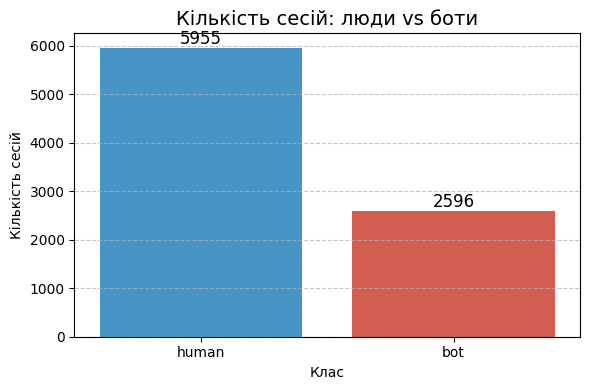


✅ Графік збережено у results/figures/class_balance.png


In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

                                           
delbot_raw = '/content/drive/MyDrive/man-bot-detection/data/raw/delbot_mouse/'

                                            
bot_count = 0
human_count_delbot = 0

for dir_name in os.listdir(delbot_raw):
    dir_path = os.path.join(delbot_raw, dir_name)
    if not os.path.isdir(dir_path):
        continue

                                               
    txt_files = [f for f in os.listdir(dir_path) if f.endswith('.txt')]
    count = len(txt_files)

    if 'bot' in dir_name.lower():
        bot_count += count
    elif 'human' in dir_name.lower():
        human_count_delbot += count

print(f"✅ Бот-сесій (DELBOT-Mouse): {bot_count}")
print(f"✅ Людських сесій (DELBOT-Mouse): {human_count_delbot}")

                                
captcha_human = 5000                      
total_human = captcha_human + human_count_delbot
total_bot = bot_count

print(f"\n📊 Загалом після об'єднання:")
print(f"   Люди (Captcha + DELBOT-human): {total_human}")
print(f"   Боти (DELBOT-bot): {total_bot}")

                                                              
                              
                                                              
data = {'label': ['human'] * total_human + ['bot'] * total_bot}
df_counts = pd.DataFrame(data)

plt.figure(figsize=(6, 4))
sns.countplot(data=df_counts, x='label', palette=['#3498db', '#e74c3c'])
plt.title('Кількість сесій: люди vs боти', fontsize=14)
plt.xlabel('Клас')
plt.ylabel('Кількість сесій')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}',
                       (p.get_x() + p.get_width()/2., p.get_height()),
                       ha='center', va='bottom', fontsize=12)

plt.tight_layout()

                   
fig_dir = '/content/drive/MyDrive/man-bot-detection/results/figures'
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(os.path.join(fig_dir, 'class_balance.png'), dpi=150)
plt.show()

print("\n✅ Графік збережено у results/figures/class_balance.png")


Завантажено 1 людських траєкторій
Завантажено 2 бот-траєкторій


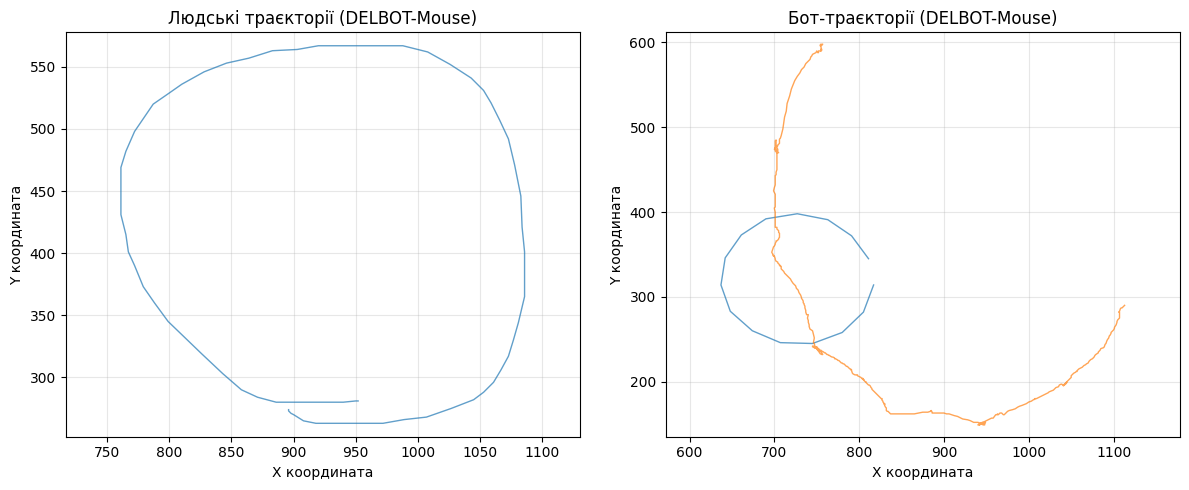

✅ Графік збережено у /content/drive/MyDrive/man-bot-detection/results/figures/trajectories_example.png


In [11]:
import os
import matplotlib.pyplot as plt

delbot_raw = '/content/drive/MyDrive/man-bot-detection/data/raw/delbot_mouse/'

def read_delbot_trajectory(file_path, max_points=500):
    """
    Читає .txt файл DELBOT-Mouse і повертає список точок (x, y) для подій Move.
    file_path: шлях до файлу
    max_points: обмеження кількості точок, щоб не перевантажувати графік
    """
    xs, ys = [], []
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines[1:]:                                         
            parts = line.strip().split(',')
            if len(parts) >= 4:
                try:
                    event_type = parts[1].strip()
                    if event_type == 'Move':
                        x = float(parts[2])
                        y = float(parts[3])
                        xs.append(x)
                        ys.append(y)
                        if len(xs) >= max_points:
                            break
                except ValueError:
                    continue
    return xs, ys

                                             
def get_first_file(dir_path, ext='.txt'):
    for f in os.listdir(dir_path):
        if f.endswith(ext):
            return os.path.join(dir_path, f)
    return None

                     
human_trajectories = []
bot_trajectories = []

               
human_dirs = [d for d in os.listdir(delbot_raw)
              if os.path.isdir(os.path.join(delbot_raw, d)) and 'human' in d]

for d in human_dirs[:2]:                                            
    dir_path = os.path.join(delbot_raw, d)
    file_path = get_first_file(dir_path)
    if file_path:
        xs, ys = read_delbot_trajectory(file_path)
        if xs and ys:
            human_trajectories.append((xs, ys))

           
bot_dirs = [d for d in os.listdir(delbot_raw)
            if os.path.isdir(os.path.join(delbot_raw, d)) and 'bot' in d]

for d in bot_dirs[:2]:
    dir_path = os.path.join(delbot_raw, d)
    file_path = get_first_file(dir_path)
    if file_path:
        xs, ys = read_delbot_trajectory(file_path)
        if xs and ys:
            bot_trajectories.append((xs, ys))

print(f"Завантажено {len(human_trajectories)} людських траєкторій")
print(f"Завантажено {len(bot_trajectories)} бот-траєкторій")

                 
plt.figure(figsize=(12, 5))

                    
plt.subplot(1, 2, 1)
for xs, ys in human_trajectories:
    plt.plot(xs, ys, alpha=0.7, linewidth=1)
plt.title('Людські траєкторії (DELBOT-Mouse)', fontsize=12)
plt.xlabel('X координата')
plt.ylabel('Y координата')
plt.axis('equal')
plt.grid(True, alpha=0.3)

                
plt.subplot(1, 2, 2)
for xs, ys in bot_trajectories:
    plt.plot(xs, ys, alpha=0.7, linewidth=1)
plt.title('Бот-траєкторії (DELBOT-Mouse)', fontsize=12)
plt.xlabel('X координата')
plt.ylabel('Y координата')
plt.axis('equal')
plt.grid(True, alpha=0.3)

plt.tight_layout()

            
save_path = '/content/drive/MyDrive/man-bot-detection/results/figures/trajectories_example.png'
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, dpi=150)
plt.show()

print(f"✅ Графік збережено у {save_path}")

Mounted at /content/drive
Завантажено 3 файлів, загалом 1109481 рядків.
Завантажено 2 файлів, загалом 257673 рядків.
Розподіл у CIC-IDS2017:
        Attack_Type   Count
0            BENIGN  726816
1          DoS Hulk  231073
2              DDoS  128027
3     DoS GoldenEye   10293
4     DoS slowloris    5796
5  DoS Slowhttptest    5499
6               Bot    1966
7        Heartbleed      11

Розподіл у UNSW-NB15:
      Attack_Type  Count
0          Normal  93000
1         Generic  58871
2        Exploits  44525
3         Fuzzers  24246
4             DoS  16353
5  Reconnaissance  13987
6        Analysis   2677
7        Backdoor   2329
8       Shellcode   1511
9           Worms    174


/tmp/ipykernel_1428/831749818.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cic_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[0], palette='viridis') # Горизонтальна, сортована, палітра
/tmp/ipykernel_1428/831749818.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=unsw_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[1], palette='plasma') # Горизонтальна, сортована, палітра


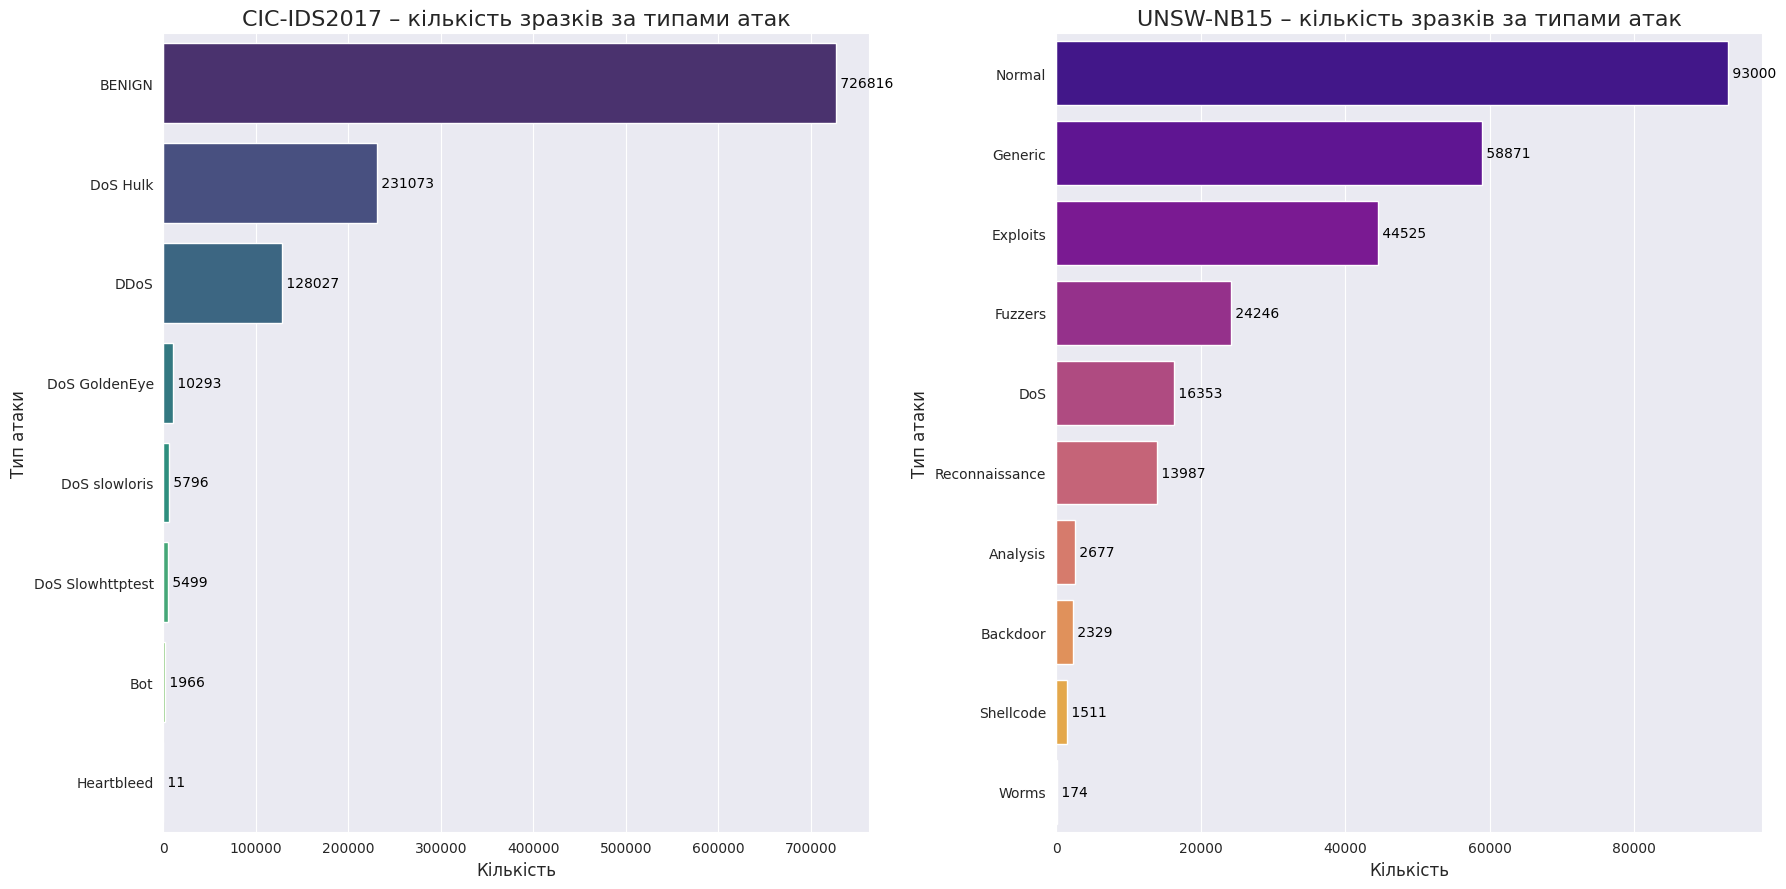

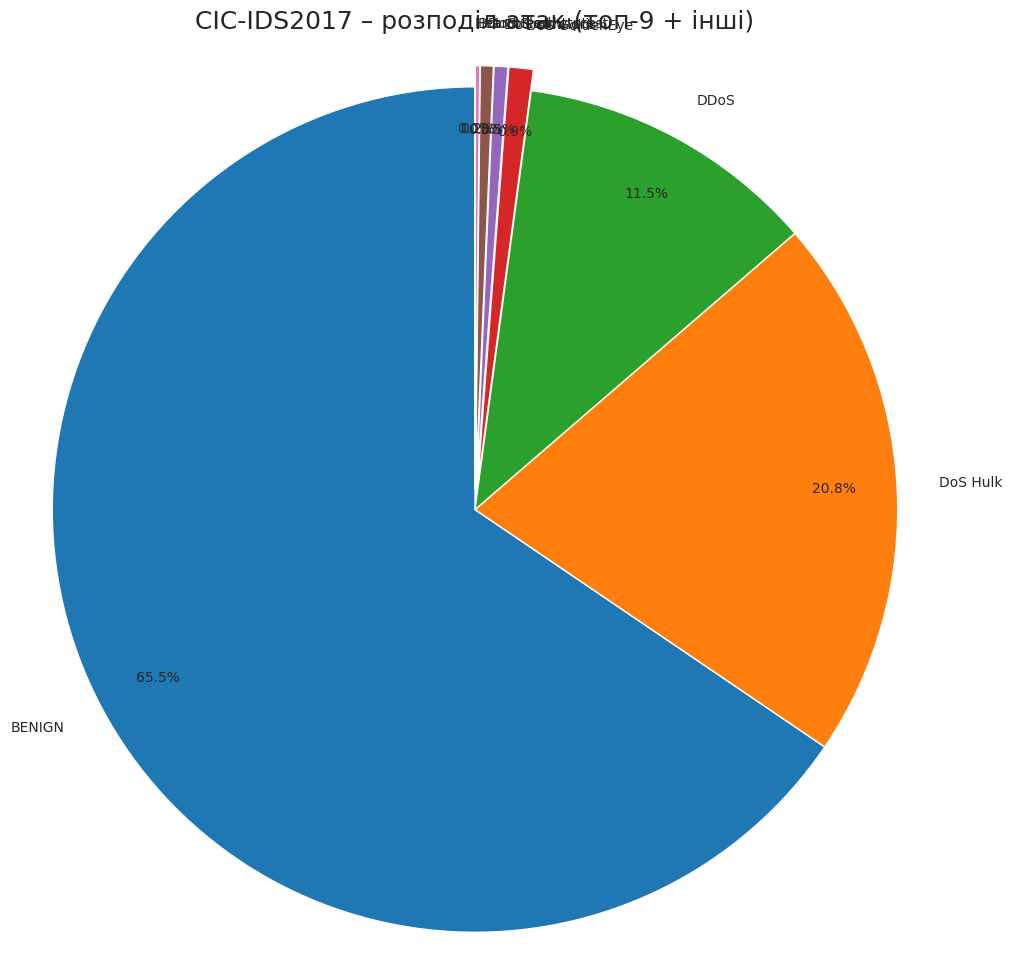

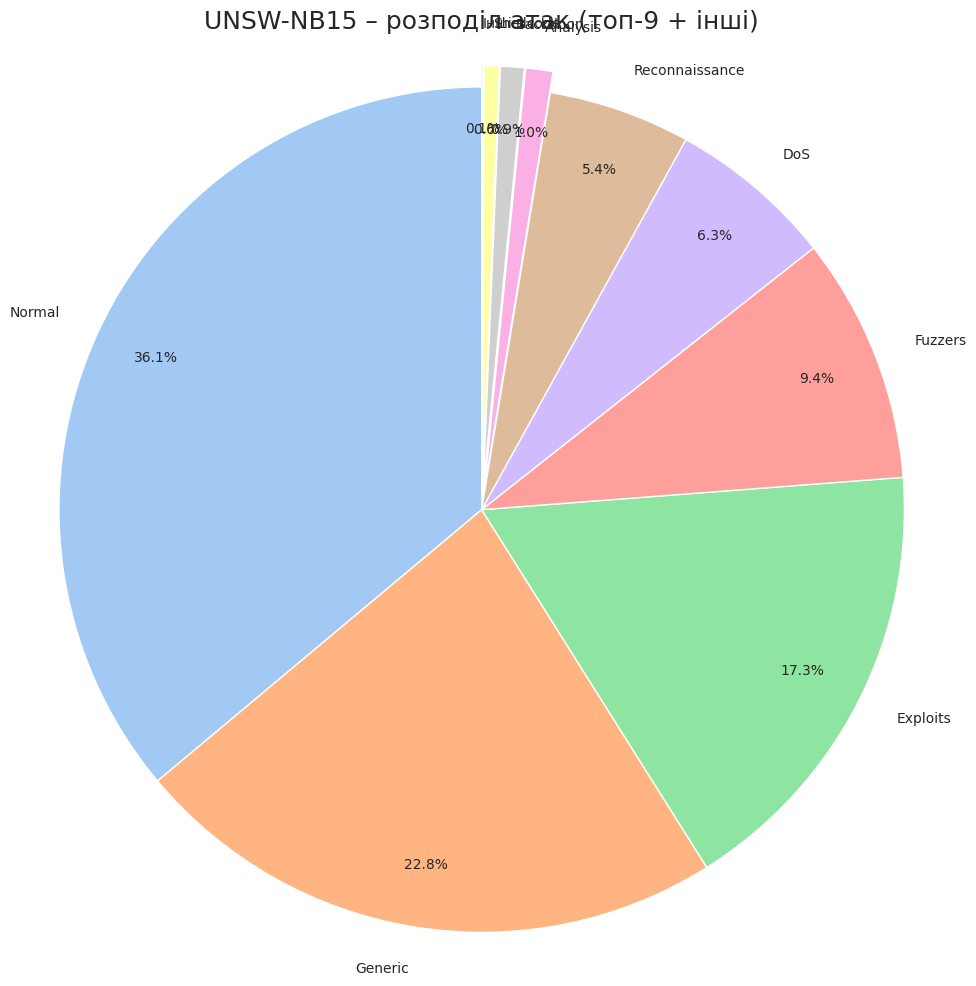

Візуалізацію завершено!


In [12]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

sns.set_style("darkgrid")                            
plt.rcParams['figure.figsize'] = (14, 8)                          

base_path = '/content/drive/MyDrive/man-bot-detection/data/raw'
def load_csvs_from_folder(folder_path):
    all_files = glob.glob(os.path.join(folder_path, '**', '*.csv'), recursive=True)
    if not all_files:
        print(f"У папці {folder_path} не знайдено CSV-файлів.")
        return None
    df_list = []
    for file in all_files:
        try:
            df = pd.read_csv(file, encoding='utf-8')
        except UnicodeDecodeError:
            df = pd.read_csv(file, encoding='latin-1')
        df_list.append(df)
    combined = pd.concat(df_list, ignore_index=True)
    print(f"Завантажено {len(all_files)} файлів, загалом {len(combined)} рядків.")
    return combined

                                                              
                    
                                                              

cic_path = os.path.join(base_path, 'cic_ids_2017')
cic_df = load_csvs_from_folder(cic_path)

unsw_path = os.path.join(base_path, 'unsw_nb15')
unsw_df = load_csvs_from_folder(unsw_path)

if cic_df is None or unsw_df is None:
    raise SystemExit("Не вдалося завантажити один із датасетів. Перевірте шлях.")

cic_label_col = None
for col in cic_df.columns:
    if col.strip().lower() == 'label':
        cic_label_col = col
        break
if cic_label_col is None:
    raise ValueError("У CIC-IDS2017 не знайдено колонку з мітками (Label).")
unsw_label_col = None
for col in unsw_df.columns:
    if col.strip().lower() == 'attack_cat' or col.strip().lower() == 'label':
        unsw_label_col = col
        break
if unsw_label_col is None:
    raise ValueError("У UNSW-NB15 не знайдено колонку з мітками (attack_cat або label).")

cic_counts = cic_df[cic_label_col].value_counts().reset_index()
cic_counts.columns = ['Attack_Type', 'Count']
print("Розподіл у CIC-IDS2017:")
print(cic_counts)

unsw_counts = unsw_df[unsw_label_col].value_counts().reset_index()
unsw_counts.columns = ['Attack_Type', 'Count']
print("\nРозподіл у UNSW-NB15:")
print(unsw_counts)

                                                              
                                       
                                                              

fig, axes = plt.subplots(1, 2, figsize=(18, 9))                          

             
sns.barplot(data=cic_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[0], palette='viridis')                                    
axes[0].set_title('CIC-IDS2017 – кількість зразків за типами атак', fontsize=16)
axes[0].set_xlabel('Кількість', fontsize=12)
axes[0].set_ylabel('Тип атаки', fontsize=12)
for index, row in cic_counts.sort_values('Count', ascending=False).iterrows():                          
    axes[0].text(row.Count, index, f' {row.Count}', color='black', ha="left", va="center")

           
sns.barplot(data=unsw_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[1], palette='plasma')                                    
axes[1].set_title('UNSW-NB15 – кількість зразків за типами атак', fontsize=16)
axes[1].set_xlabel('Кількість', fontsize=12)
axes[1].set_ylabel('Тип атаки', fontsize=12)
for index, row in unsw_counts.sort_values('Count', ascending=False).iterrows():                          
    axes[1].text(row.Count, index, f' {row.Count}', color='black', ha="left", va="center")

plt.tight_layout()
plt.show()

                                                              
                                       
                                                              

top_cic = cic_counts.sort_values('Count', ascending=False).head(9)                 
others_count_cic = cic_counts['Count'].sum() - top_cic['Count'].sum()
if others_count_cic > 0:
    top_cic = pd.concat([top_cic, pd.DataFrame([['Інші', others_count_cic]], columns=['Attack_Type', 'Count'])], ignore_index=True)

                                                 
explode_cic = [0.05 if val < top_cic['Count'].max() * 0.1 else 0 for val in top_cic['Count']]                        

plt.figure(figsize=(12, 12))                   
plt.pie(top_cic['Count'], labels=top_cic['Attack_Type'], autopct='%1.1f%%', startangle=90, explode=explode_cic, pctdistance=0.85, colors=sns.color_palette('tab10'))                                            
plt.title('CIC-IDS2017 – розподіл атак (топ-9 + інші)', fontsize=18)                          
plt.axis('equal')
plt.show()

                                                              
                                  
                                                              

top_unsw = unsw_counts.sort_values('Count', ascending=False).head(9)                 
others_unsw = unsw_counts['Count'].sum() - top_unsw['Count'].sum()
if others_unsw > 0:
    top_unsw = pd.concat([top_unsw, pd.DataFrame([['Інші', others_unsw]], columns=['Attack_Type', 'Count'])], ignore_index=True)

                                                 
explode_unsw = [0.05 if val < top_unsw['Count'].max() * 0.1 else 0 for val in top_unsw['Count']]                        

plt.figure(figsize=(12, 12))                   
plt.pie(top_unsw['Count'], labels=top_unsw['Attack_Type'], autopct='%1.1f%%', startangle=90, explode=explode_unsw, pctdistance=0.85, colors=sns.color_palette('pastel'))                                            
plt.title('UNSW-NB15 – розподіл атак (топ-9 + інші)', fontsize=18)                          
plt.axis('equal')
plt.show()

print("Візуалізацію завершено!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ CIC-IDS2017: знайдено 3 файлів
✅ CIC-IDS2017: завантажено 1109481 рядків
✅ UNSW-NB15: знайдено 2 файлів
✅ UNSW-NB15: завантажено 257673 рядків


/tmp/ipykernel_1428/3650840601.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cic_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[0], palette='viridis') # Горизонтальна, сортована, палітра
/tmp/ipykernel_1428/3650840601.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=unsw_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[1], palette='plasma') # Горизонтальна, сортована, палітра


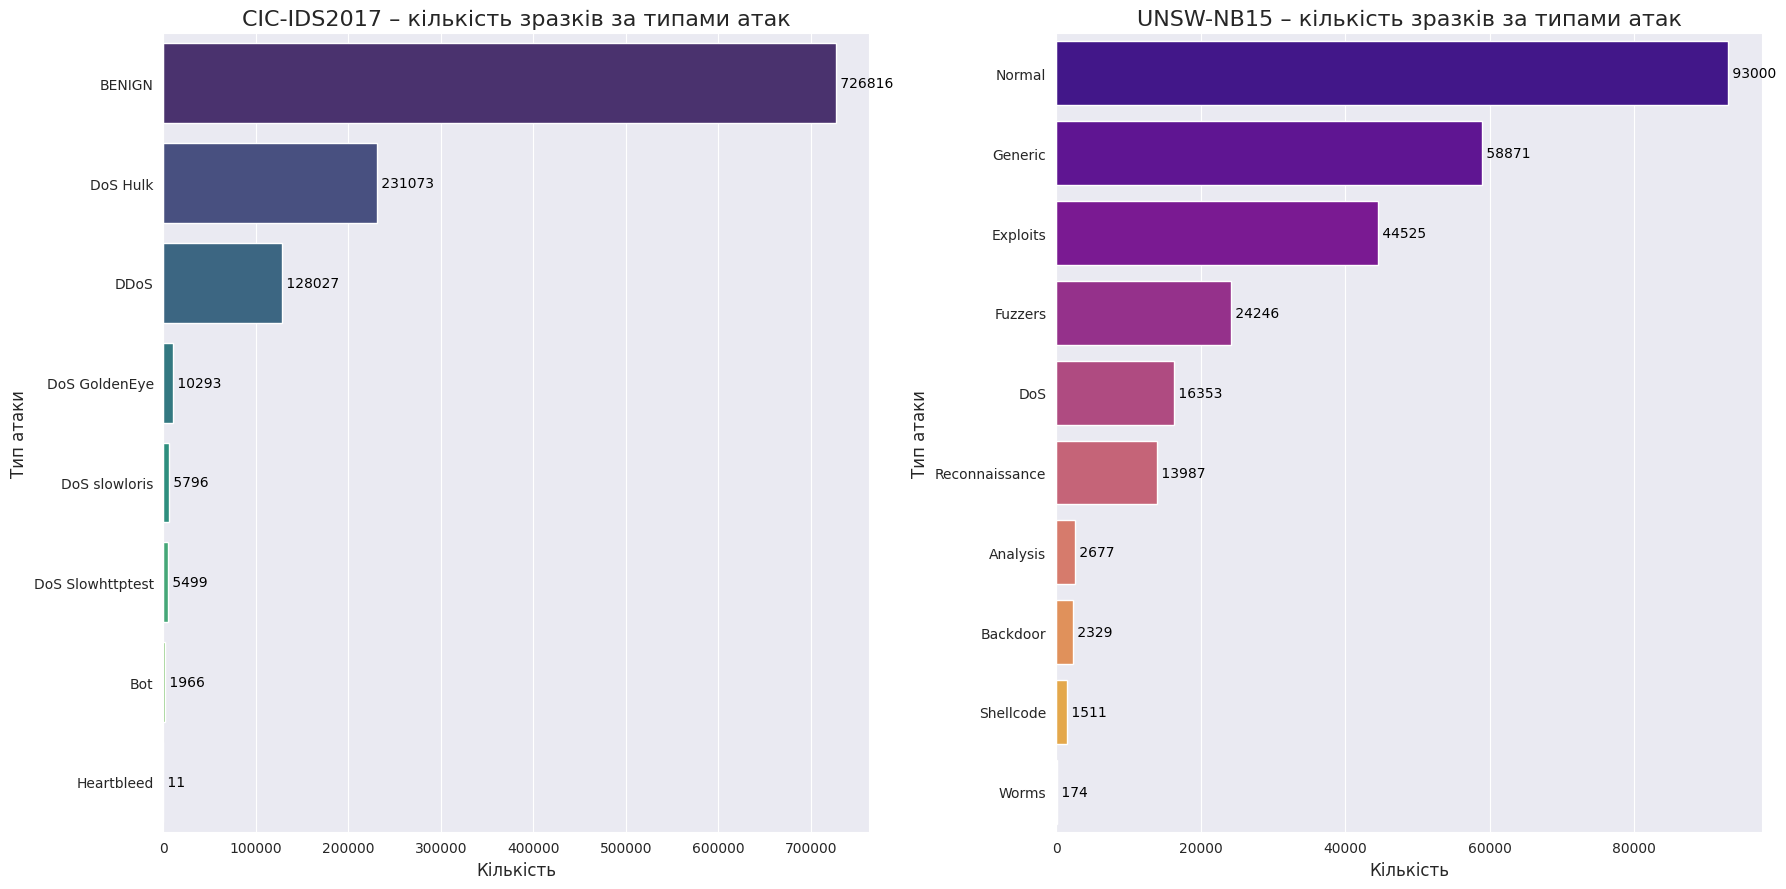

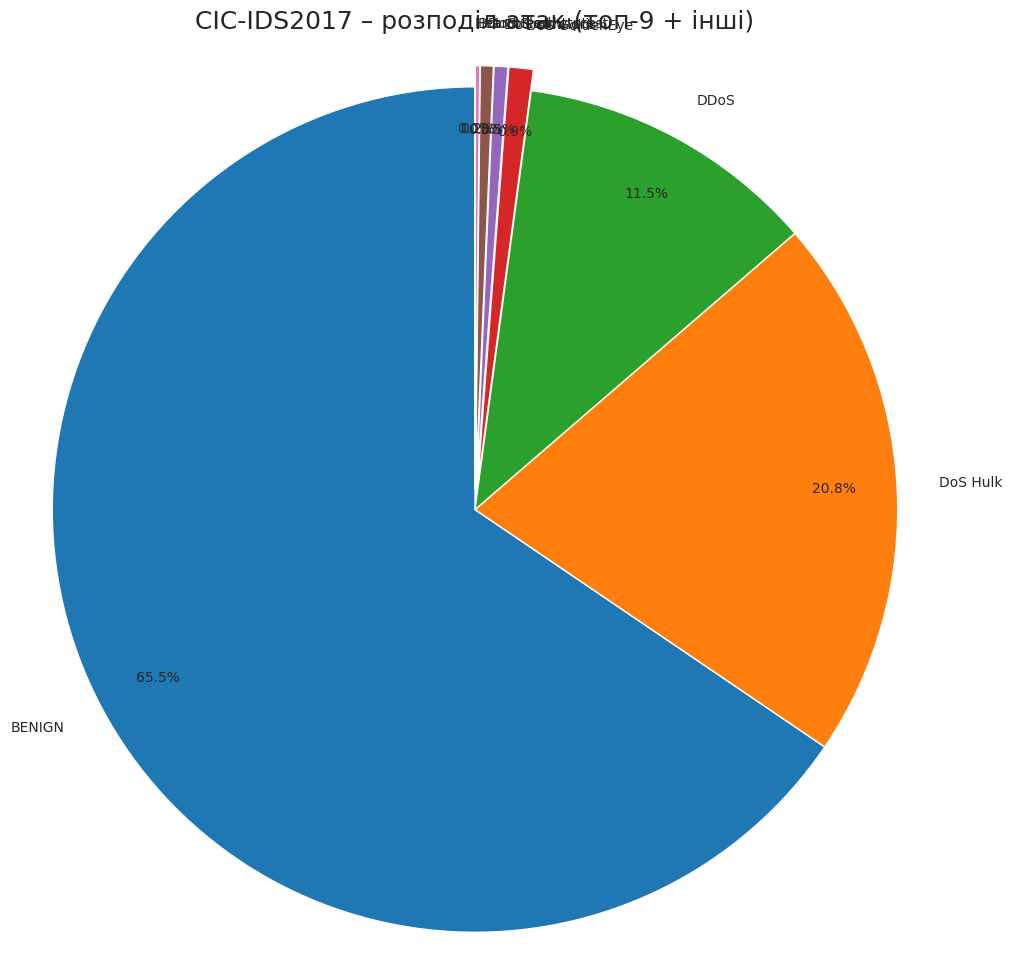

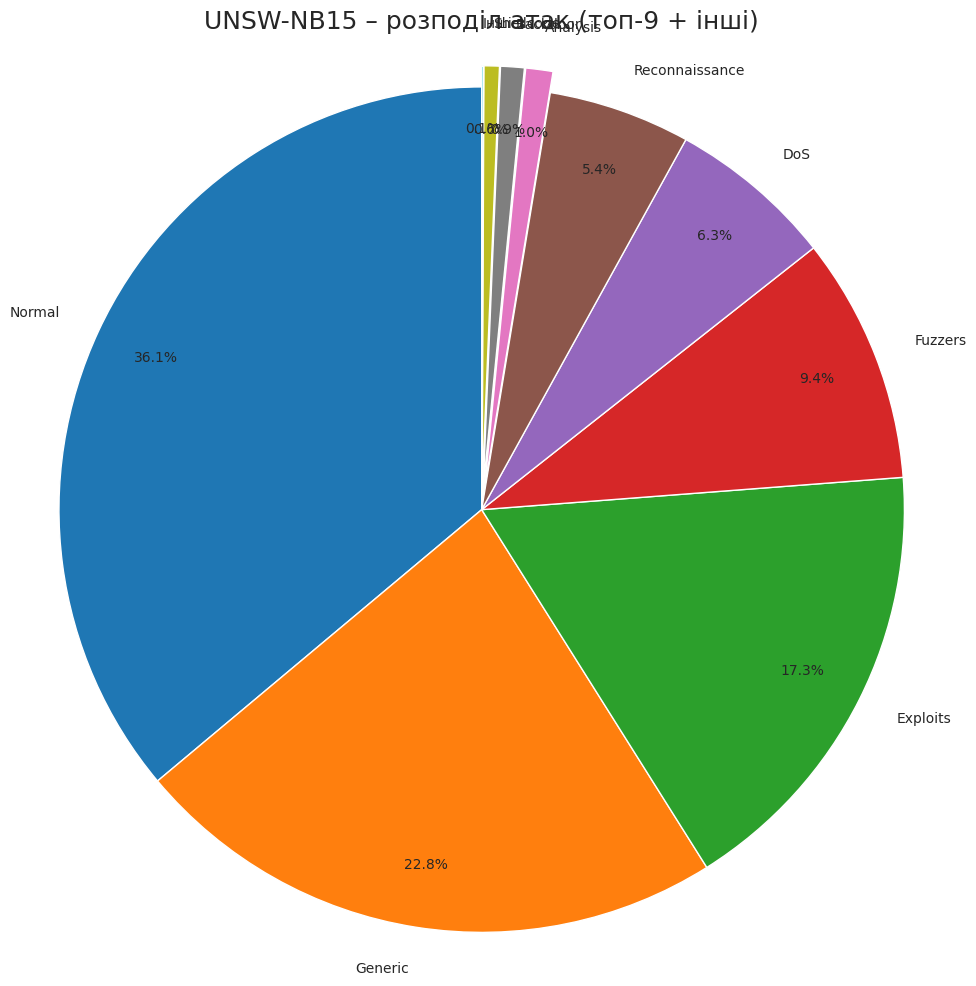


✅ Текстовий файл з висновками збережено за адресою: /content/drive/MyDrive/man-bot-detection/results/figures/Висновки_аналізу.txt

ЗМІСТ ЗГЕНЕРОВАНОГО ЗВІТУ:

            АНАЛІТИЧНИЙ ЗВІТ ТА ВИСНОВКИ
            Датасети: CIC-IDS2017 та UNSW-NB15

Дата генерації: 2026-08-19 17:17:32

-------------------------------------------------------------
1. ЗАГАЛЬНА ХАРАКТЕРИСТИКА ДАНИХ
-------------------------------------------------------------
- CIC-IDS2017: загалом 1,109,481 зразків, з них виявлено 8 унікальних типів атак.
- UNSW-NB15: загалом 257,673 зразків, з них виявлено 10 унікальних типів атак.

-------------------------------------------------------------
2. ДОМІНУЮЧІ ТИПИ АТАК (дисбаланс класів)
-------------------------------------------------------------
- У CIC-IDS2017 найпоширеніша атака — 'BENIGN' (726,816 зразків, що становить 65.51% усіх даних).
  Це свідчить про критичний дисбаланс: модель, навчена на цих даних, буде схильна ігнорувати рідкісні атаки.

- У UNSW-NB15 найпоши

In [13]:
                                                              
                                                              
                                                              

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from google.colab import drive

                                       
drive.mount('/content/drive')

                                                              
                                           
                                                              
base_path = '/content/drive/MyDrive/man-bot-detection/data/raw'                       

                                                              
                                          
                                                              
def load_data(folder_path, dataset_name):
    all_files = glob.glob(os.path.join(folder_path, '**', '*.csv'), recursive=True)
    if not all_files:
        all_files = glob.glob(os.path.join(folder_path, '**', '*.parquet'), recursive=True)
    if not all_files:
        print(f"❌ У {folder_path} не знайдено CSV/Parquet.")
        return None
    print(f"✅ {dataset_name}: знайдено {len(all_files)} файлів")

    df_list = []
    for f in all_files:
        try:
            if f.endswith('.csv'):
                df = pd.read_csv(f, encoding='utf-8', low_memory=False)
            elif f.endswith('.parquet'):
                df = pd.read_parquet(f)
            else:
                continue
            df_list.append(df)
        except Exception as e:
            print(f"Помилка читання {f}: {e}")
    if not df_list:
        return None
    combined = pd.concat(df_list, ignore_index=True)
    print(f"✅ {dataset_name}: завантажено {len(combined)} рядків")
    return combined

              
cic_df = load_data(os.path.join(base_path, 'cic_ids_2017'), 'CIC-IDS2017')
unsw_df = load_data(os.path.join(base_path, 'unsw_nb15'), 'UNSW-NB15')

if cic_df is None or unsw_df is None:
    raise SystemExit("❌ Не вдалося завантажити дані. Перевірте шлях у base_path.")

                                                              
                       
                                                              
cic_label = next((c for c in cic_df.columns if c.strip().lower() == 'label'), None)                 
unsw_label = next((c for c in unsw_df.columns if c.strip().lower() in ['attack_cat', 'label']), None)                 

if cic_label is None or unsw_label is None:
    raise ValueError("Не знайдено колонки з мітками.")

            
cic_counts = cic_df[cic_label].value_counts().reset_index()
cic_counts.columns = ['Attack_Type', 'Count']

unsw_counts = unsw_df[unsw_label].value_counts().reset_index()
unsw_counts.columns = ['Attack_Type', 'Count']

                                                              
                                  
                                                              
save_folder = os.path.join('/content/drive/MyDrive/man-bot-detection', 'results', 'figures')                                       
os.makedirs(save_folder, exist_ok=True)                                 

                                                 
fig, axes = plt.subplots(1, 2, figsize=(18, 9))                          

             
sns.barplot(data=cic_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[0], palette='viridis')                                    
axes[0].set_title('CIC-IDS2017 – кількість зразків за типами атак', fontsize=16)
axes[0].set_xlabel('Кількість', fontsize=12)
axes[0].set_ylabel('Тип атаки', fontsize=12)
for index, row in cic_counts.sort_values('Count', ascending=False).iterrows():                          
    axes[0].text(row.Count, index, f' {row.Count}', color='black', ha="left", va="center")

           
sns.barplot(data=unsw_counts.sort_values('Count', ascending=False), y='Attack_Type', x='Count', ax=axes[1], palette='plasma')                                    
axes[1].set_title('UNSW-NB15 – кількість зразків за типами атак', fontsize=16)
axes[1].set_xlabel('Кількість', fontsize=12)
axes[1].set_ylabel('Тип атаки', fontsize=12)
for index, row in unsw_counts.sort_values('Count', ascending=False).iterrows():                          
    axes[1].text(row.Count, index, f' {row.Count}', color='black', ha="left", va="center")

plt.tight_layout()
plt.savefig(os.path.join(save_folder, 'bar_charts_attacks.png'), dpi=300, bbox_inches='tight')                              
plt.show()

                                                           
def save_pie(df, title, filename):
    top = df.sort_values('Count', ascending=False).head(9)                 
    others = df['Count'].sum() - top['Count'].sum()
    if others > 0:
        top = pd.concat([top, pd.DataFrame([['Інші', others]], columns=['Attack_Type', 'Count'])], ignore_index=True)

                                                     
    explode = [0.05 if val < top['Count'].max() * 0.1 else 0 for val in top['Count']]                        

    plt.figure(figsize=(12, 12))                   
    plt.pie(top['Count'], labels=top['Attack_Type'], autopct='%1.1f%%', startangle=90, explode=explode, pctdistance=0.85, colors=sns.color_palette('tab10'))                                            
    plt.title(title, fontsize=18)                          
    plt.axis('equal')
    plt.savefig(os.path.join(save_folder, filename), dpi=300, bbox_inches='tight')                              
    plt.show()

save_pie(cic_counts, 'CIC-IDS2017 – розподіл атак (топ-9 + інші)', 'pie_cic.png')
save_pie(unsw_counts, 'UNSW-NB15 – розподіл атак (топ-9 + інші)', 'pie_unsw.png')

                                                              
                                            
                                                              
                                       
cic_total = cic_counts['Count'].sum()
unsw_total = unsw_counts['Count'].sum()

cic_top1 = cic_counts.iloc[0]['Attack_Type']
cic_top1_count = cic_counts.iloc[0]['Count']
cic_top1_pct = (cic_top1_count / cic_total) * 100

unsw_top1 = unsw_counts.iloc[0]['Attack_Type']
unsw_top1_count = unsw_counts.iloc[0]['Count']
unsw_top1_pct = (unsw_top1_count / unsw_total) * 100

                                 
cic_unique = len(cic_counts)
unsw_unique = len(unsw_counts)

                          
conclusions_text = f"""
=============================================================
            АНАЛІТИЧНИЙ ЗВІТ ТА ВИСНОВКИ
            Датасети: CIC-IDS2017 та UNSW-NB15
=============================================================

Дата генерації: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}

-------------------------------------------------------------
1. ЗАГАЛЬНА ХАРАКТЕРИСТИКА ДАНИХ
-------------------------------------------------------------
- CIC-IDS2017: загалом {cic_total:,} зразків, з них виявлено {cic_unique} унікальних типів атак.
- UNSW-NB15: загалом {unsw_total:,} зразків, з них виявлено {unsw_unique} унікальних типів атак.

-------------------------------------------------------------
2. ДОМІНУЮЧІ ТИПИ АТАК (дисбаланс класів)
-------------------------------------------------------------
- У CIC-IDS2017 найпоширеніша атака — '{cic_top1}' ({cic_top1_count:,} зразків, що становить {cic_top1_pct:.2f}% усіх даних).
  Це свідчить про критичний дисбаланс: модель, навчена на цих даних, буде схильна ігнорувати рідкісні атаки.

- У UNSW-NB15 найпоширеніша атака — '{unsw_top1}' ({unsw_top1_count:,} зразків, {unsw_top1_pct:.2f}%).
  Хоча тут дисбаланс менш виражений, ніж у CIC, але все одно потребує спеціальних методів боротьби (наприклад, зважування класів або аугментація).

-------------------------------------------------------------
3. ПОРІВНЯЛЬНИЙ АНАЛІЗ
-------------------------------------------------------------
- CIC-IDS2017 містить значну кількість атак типу DoS/DDoS (особливо Hulk, GoldenEye) та сканування портів.
  Це робить його ідеальним для тестування систем виявлення аномалій у трафіку з великим навантаженням.

- UNSW-NB15 включає більше сучасних векторів атак, таких як Exploits, Generic та Reconnaissance.
  Він краще підходить для оцінки моделей машинного навчання на сучасних загрозах, ніж застарілі NSL-KDD.

-------------------------------------------------------------
4. РЕКОМЕНДАЦІЇ ДЛЯ МОДЕЛЮВАННЯ
-------------------------------------------------------------
- Через високий дисбаланс у CIC-IDS2017 рекомендую використовувати метрики F1-Score (макро/важене) або Precision-Recall AUC замість звичайної Accuracy.
- Для обох датасетів доцільно застосувати техніки семплювання (SMOTE, ADASYN) або використовувати ансамблеві методи (XGBoost, Random Forest) з налаштуванням параметра class_weight.

-------------------------------------------------------------
5. ЗАГАЛЬНИЙ ВИСНОВОК
-------------------------------------------------------------
Візуалізація підтверджує, що обидва датасети є типовими представниками задач кібербезпеки з нерівномірним розподілом класів.
Для побудови якісної моделі виявлення вторгнень (NIDS) необхідно приділити особливу увагу попередній обробці даних та коректному вибору метрик оцінювання.
Отримані стовпчикові та кругові діаграми (файли bar_charts_attacks.png, pie_cic.png, pie_unsw.png) наочно демонструють ці закономірності.

=============================================================
"""

                                     
conclusions_path = os.path.join(save_folder, 'Висновки_аналізу.txt')
with open(conclusions_path, 'w', encoding='utf-8') as f:
    f.write(conclusions_text)

print(f"\n✅ Текстовий файл з висновками збережено за адресою: {conclusions_path}")

                                                
print("\n" + "="*60)
print("ЗМІСТ ЗГЕНЕРОВАНОГО ЗВІТУ:")
print("="*60)
print(conclusions_text)

print("\n🎯 Робота завершена! Графіки та текст збережені на вашому Google Диску.")